# 02 · Modelo de pronóstico

**Grupo 2 · Big Data e IA aplicada** · Industria 4.0, FIUNA · Caso Casa Rojas (Fideos Napoli)

**Lo muestra:** Franco · **Escalón 3 de la exposición:** anticipar

Este notebook responde: **con todos los datos disponibles, ¿el machine learning le gana a los
métodos simples, y por cuánto?** Arranca desde el panel limpio del notebook 01.

| Sección | Qué hace |
|---|---|
| 1. Carga | Lee el panel mensual de 01 |
| 2. El problema | Qué se pronostica y por qué la validación es temporal |
| 3. Variables | Qué mira el modelo, con la verificación antifuga |
| 4. Métricas | MAE, WAPE, sesgo y MASE, verificadas con el ejemplo de la guía |
| 5. Selección en 2015 | Ventana de la media móvil y pérdida de LightGBM |
| 6. Prueba en 2016 | Los siete modelos, con su dispersión |
| 7. Dónde gana y dónde pierde | Por depósito, clase ABC e intermitencia |
| 8. Modelo final | Pronóstico de febrero de 2017 para Power BI |
| 9. Qué mira el modelo | Importancia de variables y coeficientes |
| 10. Rango | El intervalo P10-P90 y su cobertura medida |
| 11. Demo | Una serie, su historia y su pronóstico |
| 12. Anexo | Regresión logística: ¿habrá pedido? |

> Para la demo en vivo, dejar `RECALCULAR = False`: los resultados del backtest se releen de
> `resultados/cache/` y el notebook corre en segundos. Con `True` se recalcula todo (unos 20 minutos).

In [1]:
# Preparación: el mismo bloque funciona en Google Colab y en local.
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    # Carpeta del repo dentro de Drive. Cambiala si la subiste con otro nombre.
    RAIZ = Path("/content/drive/MyDrive/Industria40")
    import importlib.util

    faltan = [m for m in ('statsforecast',) if importlib.util.find_spec(m) is None]
    if faltan:
        get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(RAIZ / "src"))
print("Repo en:", RAIZ)

Repo en: C:\Users\franc\Desktop\Desk\Projects\Private\Industria40


In [2]:
RECALCULAR = False  # True: vuelve a entrenar todo. False: relee la caché si existe.

In [3]:
import json
import platform

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import statsforecast

from demanda import backtest as B
from demanda import config as cfg
from demanda import datos as D
from demanda import features as F
from demanda import graficos as G
from demanda import metricas as M
from demanda import modelos as Mo

G.estilo()
cfg.asegurar_carpetas()
CACHE = cfg.RESULTADOS / "cache"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
print(
    f"Python {platform.python_version()} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · "
    f"LightGBM {lightgbm.__version__} · statsforecast {statsforecast.__version__}"
)

Python 3.12.4 · pandas 2.3.3 · scikit-learn 1.9.1 · LightGBM 4.7.0 · statsforecast 2.1.1


## 1. Carga

In [4]:
largo = D.leer_panel()
panel = D.panel_desde_largo(largo)
dim = pd.read_parquet(cfg.ARCHIVO_DIM_SERIE)
assert (dim["serie"].to_numpy() == panel.series["serie"].to_numpy()).all(), "dim_serie y el panel tienen que tener el mismo orden"
verdad = panel.Y
print(f"{G.num(len(panel.series))} series × {panel.n_meses} meses, de {cfg.MES_INICIO} a {cfg.MES_FIN}")

2.849 series × 60 meses, de 2012-01 a 2016-12


## 2. El problema

- **Qué se pronostica:** la demanda mensual de cada producto en cada depósito, 2.849 series.
- **Con cuánta anticipación:** con los datos hasta el cierre del mes `t` se pronostica el mes
  `t + 2`. Es el problema que declara la empresa del dataset, porque sus productos tardan más de
  un mes en llegar a los depósitos. Para Casa Rojas equivale a decidir hoy la producción que va a
  llegar a Encarnación o a Ciudad del Este dentro de dos meses.
- **Por qué la validación es temporal y no al azar:** si se mezclan meses al azar, el modelo
  aprende con meses posteriores a los que después tiene que pronosticar. Es como estudiar con el
  examen resuelto. En la validación de **origen móvil** (Tashman, 2000) se entrena hasta una fecha,
  se prueba después y se repite desde varias fechas.

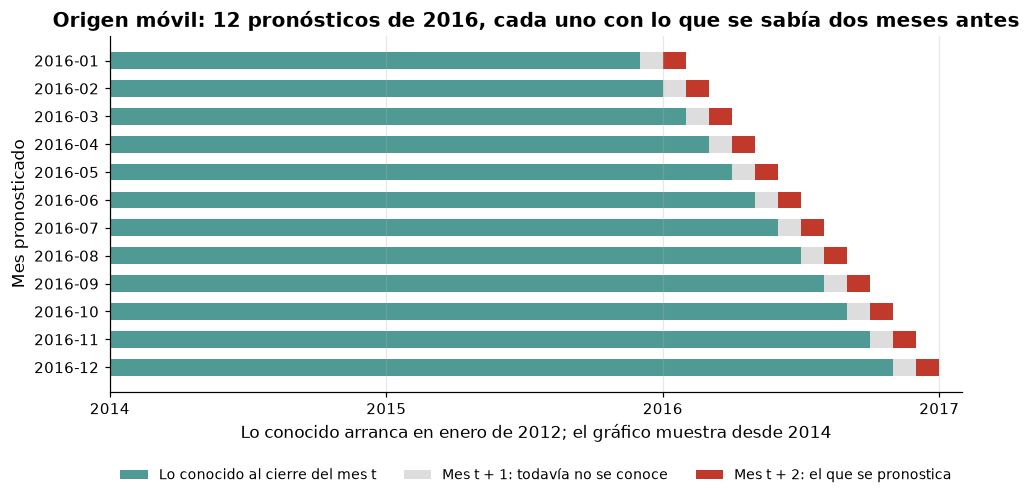

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, mes in enumerate(cfg.MESES_PRUEBA):
    o = (mes - cfg.HORIZONTE - cfg.MES_INICIO).n
    t = (mes - cfg.MES_INICIO).n
    ax.barh(i, o + 1, left=0, color="#4f9a94", height=0.6, label="Lo conocido al cierre del mes t" if i == 0 else None)
    ax.barh(i, t - o - 1, left=o + 1, color="#dddddd", height=0.6, label="Mes t + 1: todavía no se conoce" if i == 0 else None)
    ax.barh(i, 1, left=t, color="#c0392b", height=0.6, label="Mes t + 2: el que se pronostica" if i == 0 else None)
ax.set_yticks(range(len(cfg.MESES_PRUEBA)), [str(m) for m in cfg.MESES_PRUEBA])
ax.invert_yaxis()
ax.set_xticks(range(24, 61, 12), ["2014", "2015", "2016", "2017"])
ax.set_xlim(24, 61)
ax.set_ylabel("Mes pronosticado")
ax.set_title("Origen móvil: 12 pronósticos de 2016, cada uno con lo que se sabía dos meses antes")
ax.set_xlabel("Lo conocido arranca en enero de 2012; el gráfico muestra desde 2014")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
ax.grid(axis="y", visible=False)
G.guardar(fig, "02_origen_movil")
plt.show()

## 3. Variables (features)

Todas se calculan con datos hasta el origen `t`, nunca después.

| Variable | Qué es |
|---|---|
| `rez_0` … `rez_11` | La demanda de `t`, `t − 1`, …, `t − 11`. Entre ellas, `rez_10` es el mismo mes del año anterior |
| `media_3m`, `media_6m`, `media_12m` | Promedios móviles |
| `mediana_6m`, `mediana_12m` | Medianas: ignoran un pedido gigante suelto |
| `tasa_croston` | La tasa del método de Croston, la mejor referencia simple, como variable |
| `desvio_12m`, `frac_ceros_12m` | Qué tan variable es la serie y cuántos meses sin pedidos tiene |
| `mismo_periodo_anio_ant`, `hace_dos_anios` | El mes objetivo, uno y dos años antes |
| `nivel_log`, `antiguedad_meses` | Tamaño de la serie y cuánto hace que existe |
| `mes_objetivo`, `deposito`, `categoria` | Calendario y a qué pertenece la serie |

**Escalado por nivel.** Hay series de diez unidades por mes y series de millones. Todas las
cantidades se dividen por el nivel `s` de la serie, el promedio de sus últimos 12 meses. Así el
modelo aprende **formas** (un mes que duplica el promedio, una caída) y no tamaños. Al final la
predicción se multiplica por `s`.

In [6]:
SERIE = dim.sort_values("volumen_total", ascending=False)["serie"].iloc[0]
fila = int(np.flatnonzero(panel.series["serie"] == SERIE)[0])
PASOS = F.pasos_objetivo(panel.p)
origen_ej = panel.fin_de_mes(pd.Period("2015-10", freq="M"))
X_ej, s_ej = F.variables_origen(panel, origen_ej, PASOS)
print(f"Serie de ejemplo: {SERIE}, la de mayor volumen · origen 2015-10 · pronostica 2015-12")
print(f"Nivel s = {G.num(s_ej[fila])} unidades por mes")
X_ej.iloc[[fila]].T.rename(columns={fila: "valor (escalado por s)"})

Serie de ejemplo: Product_1359|Whse_J, la de mayor volumen · origen 2015-10 · pronostica 2015-12
Nivel s = 7.796.917 unidades por mes


,valor (escalado por s)
rez_0,0.999626
rez_1,1.06773
rez_2,0.830072
rez_3,1.064652
rez_4,1.09274
rez_5,0.984235
rez_6,1.156226
rez_7,0.966151
rez_8,0.679499
rez_9,1.298847


### Verificación antifuga

Si las variables de un origen usaran datos posteriores, el backtest mediría un modelo que sabe el
futuro. Se comprueba de la forma más directa: se reemplaza **todo** lo posterior al origen por
números al azar y las variables tienen que quedar idénticas. Como control, se altera un dato del
pasado y las variables tienen que cambiar; si no cambiaran, la prueba no estaría probando nada.

In [7]:
rng = np.random.default_rng(cfg.SEMILLA)
futuro_alterado = panel.Y.copy()
futuro_alterado[:, origen_ej + 1 :] = rng.uniform(0, 1e6, size=futuro_alterado[:, origen_ej + 1 :].shape)
X_alt, _ = F.variables_origen(panel.con_Y(futuro_alterado), origen_ej, PASOS)
pd.testing.assert_frame_equal(X_ej, X_alt)
print("Alterar el futuro no cambia ninguna variable.")

pasado_alterado = panel.Y.copy()
pasado_alterado[:, origen_ej] *= 2
X_pas, _ = F.variables_origen(panel.con_Y(pasado_alterado), origen_ej, PASOS)
assert not X_ej.equals(X_pas)
print("Control: alterar el mes del origen sí las cambia.")

# El entrenamiento de un origen solo usa ejemplos cuyo mes objetivo ya se conoce en ese origen.
_, _, meta_ent = F.ejemplos(panel, F.origenes_fin_de_mes(panel, origen_ej - max(PASOS)), PASOS)
assert (meta_ent["origen"] + meta_ent["paso"]).max() <= origen_ej
print("Ningún ejemplo de entrenamiento tiene su objetivo después del origen.")

Alterar el futuro no cambia ninguna variable.
Control: alterar el mes del origen sí las cambia.


Ningún ejemplo de entrenamiento tiene su objetivo después del origen.


## 4. Métricas

| Métrica | Qué mide | Cómo se lee |
|---|---|---|
| MAE | Error promedio, en unidades | «Nos equivocamos en promedio por 47 paquetes» |
| **WAPE** | Error total / demanda total | «Nos equivocamos en un 23 % del volumen». **Es la principal** |
| Sesgo | (Σ pronóstico − Σ demanda) / Σ demanda | «Pronosticamos un 10 % de más» |
| MASE | Error de cada serie dividido por el error típico de la serie | Pesa igual a las series grandes y a las chicas |

No se usa **MAPE**: divide el error por la demanda de cada mes, y cuando la demanda es cero la
cuenta no se puede hacer. En este panel, uno de cada seis meses de una serie vale cero.

Antes de usarlas, se verifican con los ejemplos numéricos de la guía de estudio (secciones 3.3).

In [8]:
real = np.array([200, 260, 140])
pron = np.array([220, 220, 220])
print(f"MAE   = {M.mae(real, pron):.1f} unidades".replace(".", ","))
print(f"WAPE  = {G.pct(M.wape(real, pron))}")
print(f"Sesgo = {G.pct(M.sesgo(real, pron))}")
assert round(M.mae(real, pron), 1) == 46.7
assert round(M.wape(real, pron), 3) == 0.233
assert round(M.sesgo(real, pron), 3) == 0.100

# Clasificación: 1.000 días, 30 fallas reales, 40 alarmas, 24 aciertos
y = np.zeros(1000, dtype=int)
y[:30] = 1
alarma = np.zeros(1000, dtype=int)
alarma[:24] = 1
alarma[30:46] = 1
c = M.clasificacion(y, alarma)
trivial = M.clasificacion(y, np.zeros(1000, dtype=int))
print(f"Precisión {G.pct(c['precision'])} · Recall {G.pct(c['recall'])} · F1 {G.pct(c['f1'])}")
print(f"El modelo que siempre dice «no va a fallar»: accuracy {G.pct(trivial['accuracy'])}, recall {G.pct(trivial['recall'])}")
assert (c["alarmas"], c["aciertos"]) == (40, 24)
assert round(c["precision"], 2) == 0.60 and round(c["recall"], 2) == 0.80 and round(c["f1"], 3) == 0.686
print("Las métricas reproducen los ejemplos de la guía.")

MAE   = 46,7 unidades
WAPE  = 23,3 %
Sesgo = 10,0 %
Precisión 60,0 % · Recall 80,0 % · F1 68,6 %
El modelo que siempre dice «no va a fallar»: accuracy 97,0 %, recall 0,0 %
Las métricas reproducen los ejemplos de la guía.


**Cómo leer el MASE.** El denominador es el error que comete, **dentro de la historia**, el
pronóstico «el mes que viene igual que este» (Hyndman y Koehler, 2006). El numerador es el error
del modelo **a dos meses y fuera de la historia**, que es una tarea más difícil. Por eso un
método simple puede dar un MASE mayor que 1 sin estar mal calculado: lo que importa es comparar
los MASE entre modelos, no contra el 1.

## 5. Selección en 2015

Dos decisiones se toman con los pronósticos de 2015, y no se vuelven a tocar al ver 2016:

1. **La ventana de la media móvil** entre 3, 6 y 12 meses. Se le da al método simple su mejor
   versión: compararse contra una media móvil mal elegida sería regalarle la victoria al ML.
2. **La pérdida de LightGBM**, entre L1 (error absoluto) y L2 (error cuadrático), las dos
   ponderadas por el nivel de la serie. Con ese peso, la L1 equivale al error absoluto en
   unidades, que es lo que mide el WAPE. Gana la de menor WAPE; si difieren menos del 1 %, la de
   menor sesgo.

In [9]:
candidatos = [
    Mo.MediaMovil(3),
    Mo.MediaMovil(6),
    Mo.MediaMovil(12),
    Mo.LightGBM("l1", nombre="LightGBM L1"),
    Mo.LightGBM("l2", nombre="LightGBM L2"),
]
pred_sel = B.con_cache(
    CACHE / "seleccion_2015.parquet",
    RECALCULAR,
    lambda: B.correr(panel, verdad, cfg.MESES_SELECCION, candidatos, etiqueta="Selección"),
)
po_sel, res_sel = B.evaluar(pred_sel)
res_sel[["modelo", "wape", "wape_desvio", "wape_peor", "sesgo", "mase"]].round(4)

Selección 2015-02 listo en 7.2 s


Selección 2015-04 listo en 7.4 s


Selección 2015-06 listo en 8.4 s


Selección 2015-08 listo en 9.6 s


Selección 2015-10 listo en 9.4 s


Selección 2015-12 listo en 13.7 s


,modelo,wape,wape_desvio,wape_peor,sesgo,mase
0,Media móvil 3m,0.4018,0.0195,0.4235,0.0334,1.2451
1,Media móvil 6m,0.3719,0.0178,0.4011,0.0373,1.2008
2,Media móvil 12m,0.3644,0.0290,0.3960,0.0260,1.1757
3,LightGBM L1,0.3509,0.0348,0.3950,-0.0590,1.1229
4,LightGBM L2,0.3755,0.0346,0.4245,0.0410,1.2014


In [10]:
r = res_sel.set_index("modelo")
medias = r[r.index.str.startswith("Media móvil")]
K_MEDIA = int(medias["wape"].idxmin().split()[-1].rstrip("m"))
l1, l2 = r.loc["LightGBM L1"], r.loc["LightGBM L2"]
diferencia = abs(l1["wape"] - l2["wape"]) / min(l1["wape"], l2["wape"])
if diferencia < 0.01:
    OBJETIVO = "l1" if abs(l1["sesgo"]) <= abs(l2["sesgo"]) else "l2"
else:
    OBJETIVO = "l1" if l1["wape"] < l2["wape"] else "l2"
MEDIA = f"Media móvil {K_MEDIA}m"

seleccion = {
    "k_media": K_MEDIA,
    "objetivo": OBJETIVO,
    "wape_l1": float(l1["wape"]),
    "wape_l2": float(l2["wape"]),
    "sesgo_l1": float(l1["sesgo"]),
    "sesgo_l2": float(l2["sesgo"]),
    "meses": [str(m) for m in cfg.MESES_SELECCION],
}
(cfg.TABLAS / "seleccion.json").write_text(json.dumps(seleccion, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Media móvil elegida: {K_MEDIA} meses (WAPE {G.pct(medias['wape'].min())})")
print(f"Pérdida de LightGBM: {OBJETIVO.upper()} · L1: WAPE {G.pct(l1['wape'])}, sesgo {G.pct(l1['sesgo'])} · L2: WAPE {G.pct(l2['wape'])}, sesgo {G.pct(l2['sesgo'])}")

Media móvil elegida: 12 meses (WAPE 36,4 %)
Pérdida de LightGBM: L1 · L1: WAPE 35,1 %, sesgo -5,9 % · L2: WAPE 37,6 %, sesgo 4,1 %


**Qué nos dice esto.** La media móvil larga le gana a la corta: en un panel tan ruidoso, promediar
más meses filtra más ruido. Y la L1 tiene un costo que hay que decir: estima la **mediana** de la
demanda, que en series con pedidos gigantes ocasionales queda por debajo del promedio. Por eso
LightGBM con L1 tiende a pronosticar de menos, y ese sesgo se reporta en la prueba.

## 6. Prueba en 2016

Los siete modelos, en los doce meses de 2016. Cada fila de la tabla resume doce pronósticos: el
promedio, el desvío entre orígenes y el peor origen. Un promedio bueno puede esconder un mes malo.

In [11]:
modelos = Mo.modelos_regresion(K_MEDIA, OBJETIVO)
ORDEN = [m.nombre for m in modelos]
pred = B.con_cache(
    CACHE / "prueba_2016.parquet",
    RECALCULAR,
    lambda: B.correr(panel, verdad, cfg.MESES_PRUEBA, modelos, k_respaldo=K_MEDIA, etiqueta="Prueba"),
)
po, res = B.evaluar(pred)
familia = pred.drop_duplicates("modelo").set_index("modelo")["familia"]

t = res.set_index("modelo").loc[ORDEN]
vs_est = {m: M.mejora(po, m, "Naive estacional") for m in ORDEN}
vs_media = {m: M.mejora(po, m, MEDIA) for m in ORDEN}
tabla = pd.DataFrame(
    {
        "Familia": familia.loc[ORDEN].map(Mo.FAMILIAS),
        "WAPE": t["wape"].map(G.pct),
        "Desvío": t["wape_desvio"].map(G.pct),
        "Peor origen": t["wape_peor"].map(G.pct),
        "Sesgo": t["sesgo"].map(G.pct),
        "MASE": t["mase"].map(lambda v: f"{v:.3f}".replace(".", ",")),
        "Mejora vs naive estacional": ["—" if m == "Naive estacional" else G.pct(vs_est[m]["mejora"]) for m in ORDEN],
        "Mejora vs media móvil": ["—" if m == MEDIA else G.pct(vs_media[m]["mejora"]) for m in ORDEN],
        "Meses que le gana a la media móvil": ["—" if m == MEDIA else f"{vs_media[m]['ganados']} de {vs_media[m]['origenes']}" for m in ORDEN],
    }
)
t.assign(
    mejora_vs_naive_estacional=[vs_est[m]["mejora"] for m in ORDEN],
    mejora_vs_media_movil=[vs_media[m]["mejora"] for m in ORDEN],
).to_csv(cfg.TABLAS / "metricas_prueba_resumen.csv")
tabla

Prueba 2016-01 listo en 60.6 s


Prueba 2016-02 listo en 57.6 s


Prueba 2016-03 listo en 54.2 s


Prueba 2016-04 listo en 51.8 s


Prueba 2016-05 listo en 56.4 s


...

Prueba 2016-09 listo en 57.5 s


Prueba 2016-10 listo en 59.8 s


Prueba 2016-11 listo en 63.5 s


Prueba 2016-12 listo en 57.8 s


,Familia,WAPE,Desvío,Peor origen,Sesgo,MASE,Mejora vs naive estacional,Mejora vs media móvil,Meses que le gana a la media móvil
modelo,,,,,,,,,
Naive,Referencia simple,"44,4 %","5,5 %","53,0 %","0,5 %","1,262","16,8 %","-13,7 %",1 de 12
Naive estacional,Referencia simple,"53,3 %","6,9 %","66,4 %","11,4 %","1,384",—,"-36,6 %",0 de 12
Media móvil 12m,Referencia simple,"39,0 %","4,5 %","46,2 %","5,4 %","1,104","26,8 %",—,—
Croston SBA,Referencia simple,"38,9 %","3,1 %","42,9 %","0,9 %","1,155","27,0 %","0,3 %",4 de 12
ETS,Estadístico,"40,5 %","4,7 %","48,1 %","8,6 %","1,145","24,1 %","-3,7 %",1 de 12
Ridge,Machine learning,"37,9 %","4,6 %","49,8 %","-0,6 %","1,102","29,0 %","2,9 %",8 de 12
LightGBM,Machine learning,"35,1 %","3,4 %","40,4 %","-8,8 %","1,021","34,1 %","10,0 %",12 de 12


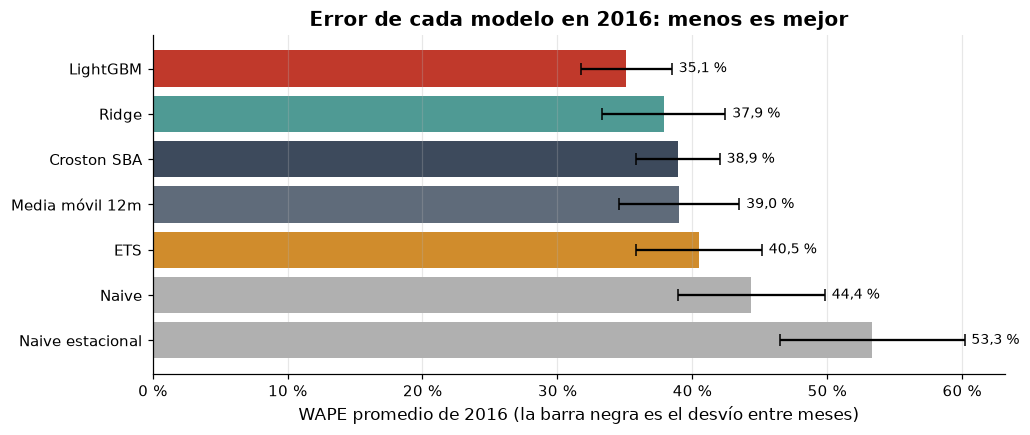

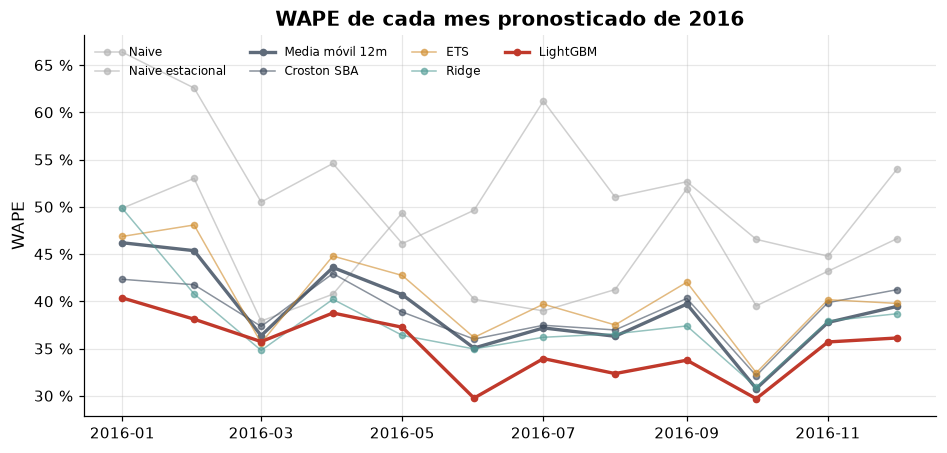

In [12]:
orden_wape = t["wape"].sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(orden_wape, t.loc[orden_wape, "wape"], xerr=t.loc[orden_wape, "wape_desvio"], color=[G.color(m) for m in orden_wape], capsize=4)
for i, m in enumerate(orden_wape):
    ax.text(t.loc[m, "wape"] + t.loc[m, "wape_desvio"] + 0.005, i, G.pct(t.loc[m, "wape"]), va="center", fontsize=9)
ax.invert_yaxis()
G.porcentaje(ax, "x")
ax.set_xlabel("WAPE promedio de 2016 (la barra negra es el desvío entre meses)")
ax.set_title("Error de cada modelo en 2016: menos es mejor")
ax.grid(axis="y", visible=False)
G.guardar(fig, "02_wape_modelos")
plt.show()

fig, ax = plt.subplots()
for m in ORDEN:
    g = po[po["modelo"] == m]
    destacado = m in ("LightGBM", MEDIA)
    ax.plot(g["mes"].dt.to_timestamp(), g["wape"], marker="o", ms=4, color=G.color(m), lw=2.2 if destacado else 1, alpha=1 if destacado else 0.6, label=m)
G.porcentaje(ax)
ax.set_ylabel("WAPE")
ax.set_title("WAPE de cada mes pronosticado de 2016")
ax.legend(ncol=4, fontsize=8, loc="upper left")
G.guardar(fig, "02_wape_por_mes")
plt.show()

In [13]:
mejor = t["wape"].idxmin()
mejor_simple = t.loc[[m for m in ORDEN if familia[m] == "referencia"], "wape"].idxmin()
print(f"Mejor modelo: {mejor}, WAPE {G.pct(t.loc[mejor, 'wape'])} ± {G.pct(t.loc[mejor, 'wape_desvio'])}.")
print(f"Mejor referencia simple: {mejor_simple}, WAPE {G.pct(t.loc[mejor_simple, 'wape'])}.")
print(f"{mejor} mejora {G.pct(vs_media[mejor]['mejora'])} sobre la media móvil y gana {vs_media[mejor]['ganados']} de {vs_media[mejor]['origenes']} meses.")
print(f"Contra el naive estacional, la mejora es de {G.pct(vs_est[mejor]['mejora'])}.")
print(f"Sesgo de {mejor}: {G.pct(t.loc[mejor, 'sesgo'])} · de la media móvil: {G.pct(t.loc[MEDIA, 'sesgo'])}.")

# Para Power BI
po.assign(origen=(po["mes"] - cfg.HORIZONTE).astype(str), mes=po["mes"].dt.to_timestamp().dt.strftime("%Y-%m-%d"))[
    ["modelo", "origen", "mes", "mae", "wape", "sesgo", "mase"]
].to_csv(cfg.POWERBI / "metricas_modelos.csv", index=False)
pred.assign(mes=pred["mes"].dt.to_timestamp().dt.strftime("%Y-%m-%d"))[["serie", "mes", "modelo", "real", "pronostico"]].to_csv(
    cfg.POWERBI / "hecho_pronostico_backtest.csv", index=False
)

Mejor modelo: LightGBM, WAPE 35,1 % ± 3,4 %.
Mejor referencia simple: Croston SBA, WAPE 38,9 %.
LightGBM mejora 10,0 % sobre la media móvil y gana 12 de 12 meses.
Contra el naive estacional, la mejora es de 34,1 %.
Sesgo de LightGBM: -8,8 % · de la media móvil: 5,4 %.


**Qué nos dice esto.**

- **El ML gana, y de forma consistente, pero por un margen moderado.** LightGBM le gana a la media
  móvil mes a mes, no solo en el promedio. Aun así, los métodos simples bien elegidos (media móvil
  larga, Croston) quedan cerca: es lo mismo que mostró la competencia M4 en series mensuales, donde
  un buen método simple es difícil de vencer.
- **El naive estacional es la peor referencia.** Copiar el mismo mes del año anterior arrastra
  todo el ruido de ese mes. La estacionalidad de este panel no es tan fuerte como para pagar ese
  ruido.
- **ETS no le gana a la media móvil.** Ajustar un modelo por serie con pocos años de historia y
  mucho ruido no compra nada, y es el modelo más lento.
- **Ridge queda en el medio.** Con las mismas variables que LightGBM no llega: una parte de la
  ventaja de LightGBM es el algoritmo, no solo las variables.
- **El sesgo de LightGBM es negativo**, por la pérdida L1. Para reponer stock eso importa: pedir de
  menos es quedarse sin producto. En la operación se corrige con el rango de la sección 10.

## 7. Dónde gana y dónde pierde

El WAPE de cada segmento junta los doce meses de 2016. La columna `volumen` dice cuánto pesa el
segmento: una mejora en un segmento chico mueve poco el total.

In [14]:
seg = pred.merge(dim[["serie", "deposito", "clase_abc", "intermitencia"]], on="serie")


def wape_por(columna):
    w = seg.groupby([columna, "modelo"]).apply(lambda g: M.wape(g["real"], g["pronostico"]), include_groups=False).unstack("modelo")[ORDEN]
    vol = seg[seg["modelo"] == ORDEN[0]].groupby(columna)["real"].sum()
    w.insert(0, "volumen", vol / vol.sum())
    w["mejor"] = w[ORDEN].idxmin(axis=1)
    return w


segmentos = {"Depósito": wape_por("deposito"), "Clase ABC": wape_por("clase_abc"), "Intermitencia": wape_por("intermitencia")}
for nombre, w in segmentos.items():
    print(nombre)
    display(w.assign(**{c: w[c].map(G.pct) for c in ["volumen", *ORDEN]}))

Depósito


modelo,volumen,Naive,Naive estacional,Media móvil 12m,Croston SBA,ETS,Ridge,LightGBM,mejor
deposito,,,,,,,,,
Whse_A,"3,0 %","74,6 %","73,7 %","60,8 %","57,5 %","65,8 %","59,4 %","53,1 %",LightGBM
Whse_C,"13,3 %","70,6 %","71,4 %","54,7 %","54,8 %","57,4 %","54,3 %","53,3 %",LightGBM
Whse_J,"69,2 %","32,4 %","35,2 %","25,7 %","25,2 %","27,1 %","26,1 %","24,8 %",LightGBM
Whse_S,"14,6 %","69,3 %","117,7 %","82,5 %","85,2 %","82,3 %","73,6 %","63,4 %",LightGBM


Clase ABC


modelo,volumen,Naive,Naive estacional,Media móvil 12m,Croston SBA,ETS,Ridge,LightGBM,mejor
clase_abc,,,,,,,,,
A,"79,8 %","37,6 %","44,9 %","32,6 %","32,4 %","33,8 %","31,8 %","29,8 %",LightGBM
B,"15,2 %","64,5 %","79,4 %","58,9 %","58,7 %","61,2 %","56,7 %","51,9 %",LightGBM
C,"5,1 %","85,4 %","105,3 %","76,8 %","79,9 %","79,6 %","75,2 %","66,9 %",LightGBM


Intermitencia


modelo,volumen,Naive,Naive estacional,Media móvil 12m,Croston SBA,ETS,Ridge,LightGBM,mejor
intermitencia,,,,,,,,,
errática,"18,2 %","80,9 %","114,2 %","82,6 %","82,0 %","87,0 %","75,7 %","68,6 %",LightGBM
intermitente,"0,2 %","93,6 %","115,4 %","83,1 %","106,0 %","85,6 %","86,5 %","78,0 %",LightGBM
irregular,"1,6 %","106,4 %","147,4 %","110,8 %","121,4 %","116,8 %","109,4 %","93,6 %",LightGBM
suave,"80,0 %","34,4 %","37,3 %","27,4 %","27,2 %","28,0 %","27,6 %","26,2 %",LightGBM


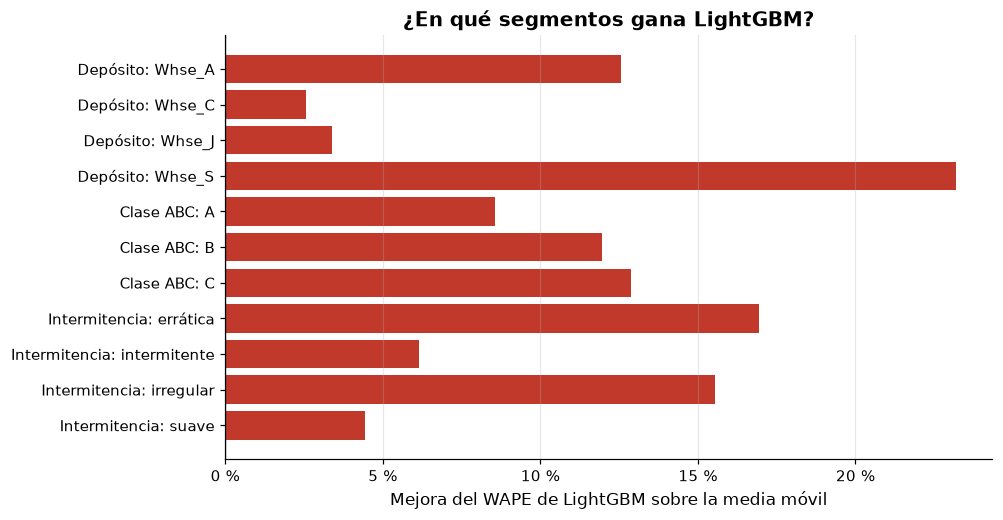

In [15]:
filas = []
for nombre, w in segmentos.items():
    for segmento, fila_w in w.iterrows():
        filas.append((f"{nombre}: {segmento}", 1 - fila_w["LightGBM"] / fila_w[MEDIA], fila_w["volumen"]))
mejora_seg = pd.DataFrame(filas, columns=["segmento", "mejora", "volumen"])

fig, ax = plt.subplots(figsize=(9, 5))
colores = ["#c0392b" if v >= 0 else "#8c8c8c" for v in mejora_seg["mejora"]]
ax.barh(mejora_seg["segmento"], mejora_seg["mejora"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
G.porcentaje(ax, "x")
ax.set_xlabel("Mejora del WAPE de LightGBM sobre la media móvil")
ax.set_title("¿En qué segmentos gana LightGBM?")
ax.grid(axis="y", visible=False)
G.guardar(fig, "02_mejora_por_segmento")
plt.show()
mejora_seg.to_csv(cfg.TABLAS / "mejora_por_segmento.csv", index=False)

**Qué nos dice esto.** LightGBM es el mejor en todos los segmentos, pero su ventaja no es pareja.
En las series grandes y regulares (el depósito principal, la clase A, la demanda suave) todos los
modelos andan parecido y la diferencia es chica. Donde más gana es en las series erráticas y
chicas, donde la media móvil se deja arrastrar por pedidos sueltos. Para una pyme la lectura es
práctica: en los productos grandes y estables una media móvil bien elegida queda cerca del ML; el
ML suma más justo en los productos que a mano son más difíciles de planificar.

## 8. Modelo final y pronóstico de febrero de 2017

Con los datos hasta diciembre de 2016 se pronostica febrero de 2017, el mes subsiguiente. Junto al
pronóstico van el P10 y el P90 (sección 10) y la media móvil, para que el dashboard pueda comparar
el modelo con la regla actual.

In [16]:
o_fin = panel.fin_de_mes(cfg.MES_FIN)
ctx_final = Mo.Contexto(panel, o_fin, PASOS, F.origenes_fin_de_mes(panel, o_fin - max(PASOS)))

lgbm_final = Mo.LightGBM(OBJETIVO)
p10_final = Mo.LightGBM("quantile", 0.1, "P10")
p90_final = Mo.LightGBM("quantile", 0.9, "P90")
ridge_final = Mo.RidgeGlobal()
pron = np.nan_to_num(lgbm_final.pronosticar(ctx_final))
p10 = np.nan_to_num(p10_final.pronosticar(ctx_final))
p90 = np.nan_to_num(p90_final.pronosticar(ctx_final))
ridge_final.pronosticar(ctx_final)
media_final = np.nan_to_num(Mo.MediaMovil(K_MEDIA).pronosticar(ctx_final))

# Tres modelos separados pueden cruzarse en alguna serie: el rango tiene que contener al pronóstico.
cruzados = (p10 > pron) | (p90 < pron)
futuro = pd.DataFrame(
    {
        "serie": panel.series["serie"],
        "mes": cfg.MES_FUTURO.to_timestamp().strftime("%Y-%m-%d"),
        "pronostico": pron,
        "p10": np.minimum(p10, pron),
        "p90": np.maximum(p90, pron),
        "pronostico_media_movil": media_final,
    }
)
futuro.to_csv(cfg.POWERBI / "hecho_pronostico_futuro.csv", index=False)
print(f"Pronóstico de {cfg.MES_FUTURO} para {G.num(len(futuro))} series · total {G.num(pron.sum())} unidades")
print(f"Media móvil para el mismo mes: {G.num(media_final.sum())} unidades")
print(f"Series donde el P10 o el P90 cruzaban al pronóstico y se ajustaron: {G.num(cruzados.sum())} ({G.pct(cruzados.mean())})")
print(f"Entrenado con {G.num(len(ctx_final.entrenamiento()[0]))} ejemplos en {G.num(lgbm_final.segundos_ajuste_, 1)} s")
futuro.sort_values("pronostico", ascending=False).head()

Pronóstico de 2017-02 para 2.849 series · total 73.708.247 unidades
Media móvil para el mismo mes: 82.406.547 unidades
Series donde el P10 o el P90 cruzaban al pronóstico y se ajustaron: 0 (0,0 %)
Entrenado con 156.472 ejemplos en 10,1 s


,serie,mes,pronostico,p10,p90,pronostico_media_movil
1740,Product_1359|Whse_J,2017-02-01,6.932029e+06,5.326600e+06,8.340802e+06,7.194750e+06
1587,Product_1248|Whse_J,2017-02-01,4.472651e+06,2.812249e+06,6.199465e+06,4.440917e+06
110,Product_0083|Whse_S,2017-02-01,3.424628e+06,1.882735e+06,4.735814e+06,3.790667e+06
1654,Product_1295|Whse_J,2017-02-01,2.222939e+06,1.853302e+06,2.679261e+06,2.204242e+06
1645,Product_1286|Whse_J,2017-02-01,1.798836e+06,1.468547e+06,2.068517e+06,1.734758e+06


## 9. Qué mira el modelo

La importancia de LightGBM es la ganancia total de cada variable en los árboles: cuánto bajó el
error cada vez que el modelo la usó para separar. Los coeficientes de Ridge son el efecto de una
variable estandarizada, con signo.

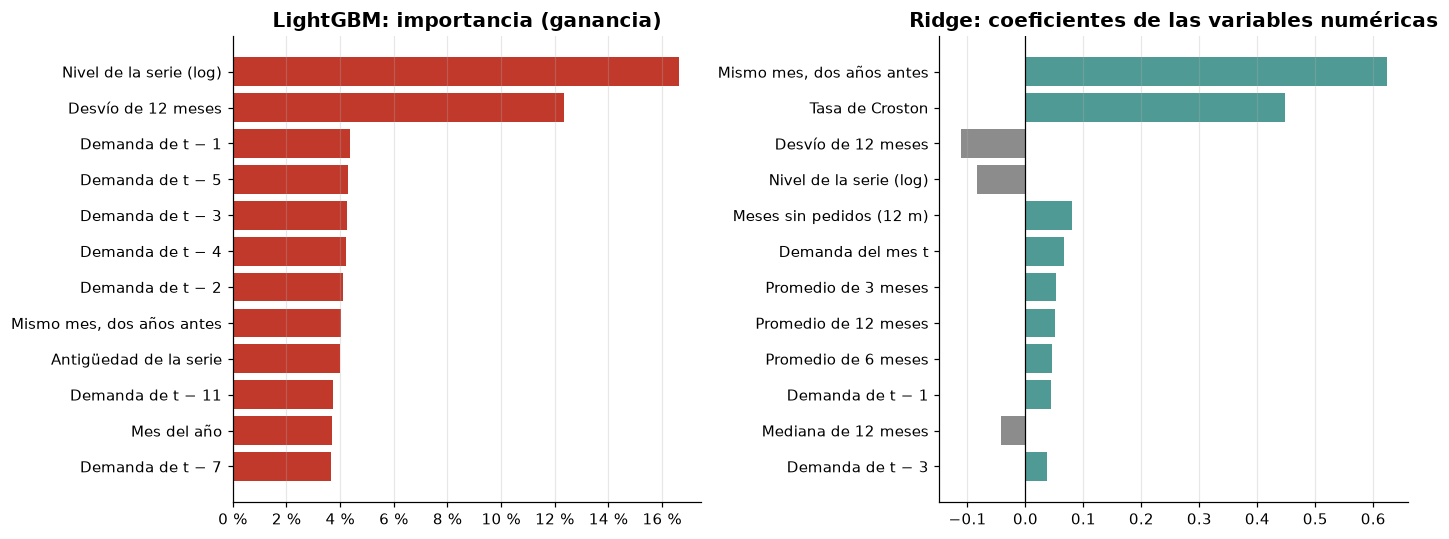

Las cinco variables más importantes de LightGBM: Nivel de la serie (log) (16,6 %), Desvío de 12 meses (12,3 %), Demanda de t − 1 (4,4 %), Demanda de t − 5 (4,3 %), Demanda de t − 3 (4,3 %)
Los tres coeficientes más grandes de Ridge: Mismo mes, dos años antes (+0,62), Tasa de Croston (+0,45), Desvío de 12 meses (-0,11)


In [17]:
NOMBRES = {
    **{f"rez_{j}": ("Demanda del mes t" if j == 0 else f"Demanda de t − {j}") for j in range(12)},
    "media_3m": "Promedio de 3 meses",
    "media_6m": "Promedio de 6 meses",
    "media_12m": "Promedio de 12 meses",
    "mediana_6m": "Mediana de 6 meses",
    "mediana_12m": "Mediana de 12 meses",
    "tasa_croston": "Tasa de Croston",
    "desvio_12m": "Desvío de 12 meses",
    "frac_ceros_12m": "Meses sin pedidos (12 m)",
    "nivel_log": "Nivel de la serie (log)",
    "antiguedad_meses": "Antigüedad de la serie",
    "mismo_periodo_anio_ant": "Mismo mes, año anterior",
    "hace_dos_anios": "Mismo mes, dos años antes",
    "mes_objetivo": "Mes del año",
    "deposito": "Depósito",
    "categoria": "Categoría",
}


def nombre_legible(columna):
    columna = columna.split("__", 1)[-1]
    if columna.startswith("missingindicator_"):
        return "Falta: " + NOMBRES.get(columna.removeprefix("missingindicator_"), columna)
    for base in ("deposito", "categoria", "mes_objetivo"):
        if columna.startswith(base + "_"):
            return f"{NOMBRES[base]} = {columna.removeprefix(base + '_')}"
    return NOMBRES.get(columna, columna)


booster = lgbm_final.ultimo_.booster_
imp = pd.Series(booster.feature_importance("gain"), index=booster.feature_name()).sort_values(ascending=False)
imp = imp / imp.sum()
pipe = ridge_final.ultimo_
coef = pd.Series(pipe.named_steps["ridge"].coef_, index=pipe.named_steps["pre"].get_feature_names_out())
# Solo las variables numéricas: los indicadores de categoría y depósito ajustan el nivel de cada
# grupo y taparían el gráfico sin decir nada sobre cómo se usa el pasado.
coef = coef[coef.index.str.startswith("num__") & ~coef.index.str.contains("missingindicator")]
coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
top = imp.head(12)
a1.barh([nombre_legible(c) for c in top.index], top.to_numpy(), color=G.color("LightGBM"))
a1.invert_yaxis()
G.porcentaje(a1, "x")
a1.set_title("LightGBM: importancia (ganancia)")
a2.barh([nombre_legible(c) for c in coef.index], coef.to_numpy(), color=["#4f9a94" if v > 0 else "#8c8c8c" for v in coef])
a2.axvline(0, color="black", lw=0.8)
a2.invert_yaxis()
a2.set_title("Ridge: coeficientes de las variables numéricas")
for a in (a1, a2):
    a.grid(axis="y", visible=False)
fig.tight_layout()
G.guardar(fig, "02_que_mira_el_modelo")
plt.show()
print("Las cinco variables más importantes de LightGBM:", ", ".join(f"{nombre_legible(c)} ({G.pct(v)})" for c, v in imp.head(5).items()))
print("Los tres coeficientes más grandes de Ridge:", ", ".join(f"{nombre_legible(c)} ({v:+.2f})".replace(".", ",") for c, v in coef.head(3).items()))

**Qué nos dice esto.** Las variables que más pesan en LightGBM no son una cantidad de un mes sino
la **forma** de la serie: qué tan variable es y qué tan grande es. Con eso el modelo decide cuánto
creerle al pasado reciente: en una serie estable sigue a los promedios y en una errática no se deja
llevar por los picos. Las demás son resúmenes del pasado (Croston, promedios, meses recientes). En
el fondo aprende una media móvil que se adapta a cada tipo de serie, y por eso gana más en las
series erráticas. Ridge, que solo puede sumar efectos en línea recta, se apoya en resúmenes
parecidos y en el mismo mes de años anteriores, pero no puede decidir «cuánto creerle al pasado»
según la serie: es la parte de la ventaja de LightGBM que viene del algoritmo. Una pyme que todavía
no tiene ML puede empezar por ahí: una media móvil bien elegida.

## 10. Rango del pronóstico

El modelo no decide por la empresa: da un pronóstico y un **rango**. Dos modelos más de LightGBM,
con pérdida cuantílica, estiman el P10 (el 10 % de los meses la demanda debería quedar por debajo)
y el P90. Si el rango está bien calibrado, la demanda real cae adentro el 80 % de las veces. Se
mide en 2016, igual que los demás modelos.

Cuantiles 2016-01 listo en 14.9 s


Cuantiles 2016-02 listo en 15.2 s


Cuantiles 2016-03 listo en 15.0 s


Cuantiles 2016-04 listo en 15.5 s


Cuantiles 2016-05 listo en 17.1 s


...

Cuantiles 2016-08 listo en 15.8 s


Cuantiles 2016-09 listo en 17.3 s


Cuantiles 2016-10 listo en 17.9 s


Cuantiles 2016-11 listo en 18.4 s


Cuantiles 2016-12 listo en 18.7 s


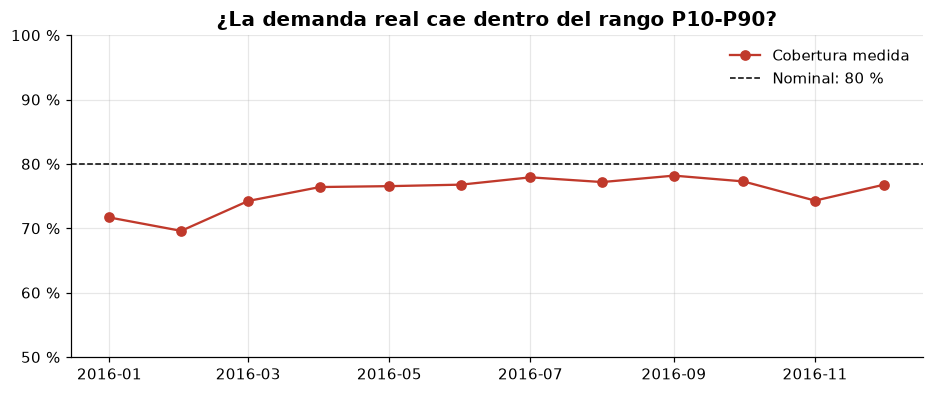

Cobertura en 2016: 75,6 % (nominal 80 %) · por debajo del P10: 11,6 % · por encima del P90: 12,8 %
Por clase ABC: A 75,1 %, B 79,4 %, C 75,1 %


In [18]:
cuantiles = [Mo.LightGBM("quantile", 0.1, "P10"), Mo.LightGBM("quantile", 0.9, "P90")]
pred_q = B.con_cache(
    CACHE / "cuantiles_2016.parquet",
    RECALCULAR,
    lambda: B.correr(panel, verdad, cfg.MESES_PRUEBA, cuantiles, k_respaldo=K_MEDIA, etiqueta="Cuantiles"),
)
bajo = pred_q[pred_q["modelo"] == "P10"][["serie", "mes", "real", "pronostico"]].rename(columns={"pronostico": "P10"})
alto = pred_q[pred_q["modelo"] == "P90"][["serie", "mes", "pronostico"]].rename(columns={"pronostico": "P90"})
q = bajo.merge(alto, on=["serie", "mes"]).merge(dim[["serie", "clase_abc"]], on="serie")
q["dentro"] = (q["P10"] <= q["real"]) & (q["real"] <= q["P90"])
q["debajo"] = q["real"] < q["P10"]
q["arriba"] = q["real"] > q["P90"]

cobertura = q["dentro"].mean()
por_mes = q.groupby("mes")["dentro"].mean()
por_clase = q.groupby("clase_abc")["dentro"].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(por_mes.index.to_timestamp(), por_mes.to_numpy(), marker="o", color=G.color("LightGBM"), label="Cobertura medida")
ax.axhline(0.8, color="black", ls="--", lw=1, label="Nominal: 80 %")
G.porcentaje(ax)
ax.set_ylim(0.5, 1)
ax.set_title("¿La demanda real cae dentro del rango P10-P90?")
ax.legend()
G.guardar(fig, "02_cobertura_rango")
plt.show()

print(f"Cobertura en 2016: {G.pct(cobertura)} (nominal 80 %) · por debajo del P10: {G.pct(q['debajo'].mean())} · por encima del P90: {G.pct(q['arriba'].mean())}")
print("Por clase ABC:", ", ".join(f"{c} {G.pct(v)}" for c, v in por_clase.items()))

**Qué nos dice esto.** La cobertura medida es la que se informa, no la nominal. Si el rango cubre
menos de lo que promete, el P90 no alcanza como stock de seguridad y hay que ensancharlo; si cubre
de más, el rango es más ancho de lo necesario. El rango sirve para decidir: el P90 es la cantidad
para un producto que no se puede quedar sin stock y el P10, para uno que se vence.

## 11. Demo: una serie

Cambiá `SERIE_DEMO` por cualquier serie de `dim_serie` (por ejemplo `"Product_1359|Whse_J"`).
Esta celda no entrena nada: usa el backtest guardado y el pronóstico de la sección 8, así que corre
en segundos.

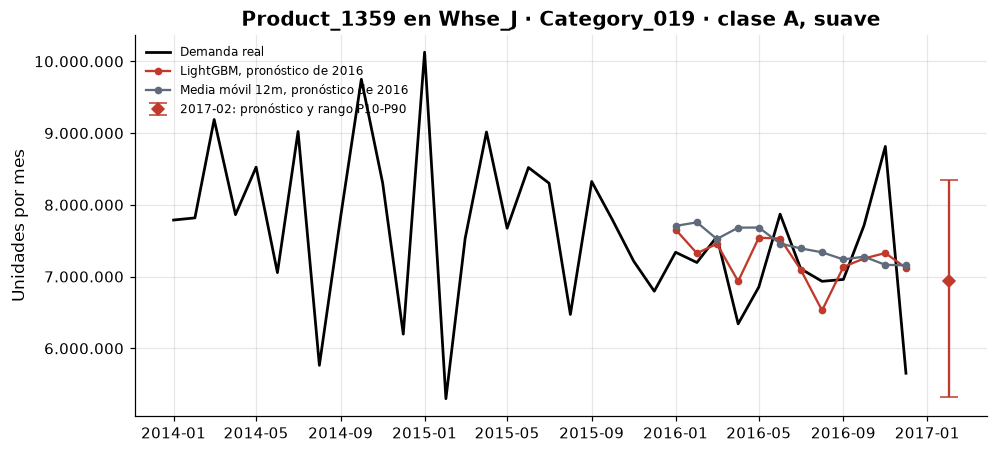

2017-02: 6.932.029 unidades, entre 5.326.600 y 8.340.802 · la media móvil diría 7.194.750


In [19]:
SERIE_DEMO = SERIE


def graficar_serie(serie, desde="2014-01"):
    i = int(np.flatnonzero(panel.series["serie"] == serie)[0])
    info = dim.iloc[i]
    meses = pd.period_range(desde, cfg.MES_FIN, freq="M")
    fig, ax = plt.subplots()
    ax.plot(meses.to_timestamp(), verdad[i, panel.indice_mes(meses[0]) :], color="black", lw=1.8, label="Demanda real")
    bt = pred[(pred["serie"] == serie) & pred["modelo"].isin(["LightGBM", MEDIA])]
    for m, g in bt.groupby("modelo"):
        ax.plot(g["mes"].dt.to_timestamp(), g["pronostico"], marker="o", ms=4, color=G.color(m), label=f"{m}, pronóstico de 2016")
    f = futuro.set_index("serie").loc[serie]
    ax.errorbar(
        [cfg.MES_FUTURO.to_timestamp()],
        [f["pronostico"]],
        yerr=[[f["pronostico"] - f["p10"]], [f["p90"] - f["pronostico"]]],
        fmt="D",
        color=G.color("LightGBM"),
        capsize=6,
        label=f"{cfg.MES_FUTURO}: pronóstico y rango P10-P90",
    )
    G.miles(ax)
    ax.set_ylabel("Unidades por mes")
    ax.set_title(f"{info['producto']} en {info['deposito']} · {info['categoria']} · clase {info['clase_abc']}, {info['intermitencia']}")
    ax.legend(fontsize=8, loc="upper left")
    return fig, f


fig, f = graficar_serie(SERIE_DEMO)
G.guardar(fig, "02_demo_serie")
plt.show()
print(f"{cfg.MES_FUTURO}: {G.num(f['pronostico'])} unidades, entre {G.num(f['p10'])} y {G.num(f['p90'])} · la media móvil diría {G.num(f['pronostico_media_movil'])}")

## 12. Anexo · Clasificación: ¿habrá algún pedido en t + 2?

Hasta acá el problema fue de **regresión** (cuánto). Una regresión logística responde una pregunta
de **clasificación** (sí o no), que es la base del mantenimiento predictivo: ¿esta máquina va a
fallar? Como el dataset no tiene fallas, se usa la pregunta comercial equivalente: ¿esta serie va a
quedar **sin pedidos** en `t + 2`? Es el evento raro, igual que una falla.

Entrena con los meses objetivo hasta diciembre de 2015 y se prueba en los doce de 2016, con las
mismas variables de los modelos de regresión. Sirve para medir con datos reales la trampa del
accuracy de la sección 3.3 de la guía.

In [20]:
ultimo_origen_ent = panel.fin_de_mes(pd.Period("2015-12", freq="M") - cfg.HORIZONTE)
X_ent, y_ent, _ = F.ejemplos(panel, F.origenes_fin_de_mes(panel, ultimo_origen_ent), PASOS)
origenes_pru = [panel.fin_de_mes(m - cfg.HORIZONTE) for m in cfg.MESES_PRUEBA]
X_pru, y_pru, _ = F.ejemplos(panel, origenes_pru, PASOS)
sin_ent = (y_ent == 0).astype(int)
sin_pru = (y_pru == 0).astype(int)

logit = Mo.clasificador_logistico(X_ent).fit(X_ent, sin_ent)
logit_bal = Mo.clasificador_logistico(X_ent, balanceado=True).fit(X_ent, sin_ent)
resultados_clf = pd.DataFrame(
    {
        "Siempre «habrá pedido»": M.clasificacion(sin_pru, np.zeros_like(sin_pru)),
        "Logística": M.clasificacion(sin_pru, logit.predict(X_pru)),
        "Logística balanceada": M.clasificacion(sin_pru, logit_bal.predict(X_pru)),
    }
).T
resultados_clf.to_csv(cfg.TABLAS / "anexo_clasificacion.csv")
print(f"Casos de prueba: {G.num(len(sin_pru))} · sin pedidos: {G.num(sin_pru.sum())} ({G.pct(sin_pru.mean())})")
resultados_clf.assign(**{c: resultados_clf[c].map(G.pct) for c in ["accuracy", "precision", "recall", "f1"]})

Casos de prueba: 34.017 · sin pedidos: 7.047 (20,7 %)


,accuracy,precision,recall,f1,alarmas,aciertos,casos
Siempre «habrá pedido»,"79,3 %","0,0 %","0,0 %","0,0 %",0.0,0.0,7047.0
Logística,"81,6 %","63,8 %","25,2 %","36,2 %",2787.0,1779.0,7047.0
Logística balanceada,"77,6 %","47,2 %","66,9 %","55,4 %",9984.0,4714.0,7047.0


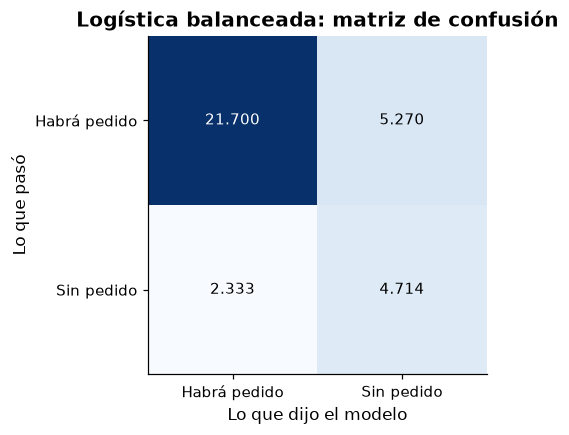

El clasificador trivial acierta el 79,3 % y no anticipa ningún mes sin pedidos (recall 0,0 %).
La logística balanceada anticipa 66,9 % de los meses sin pedidos, con precisión 47,2 %.


In [21]:
from sklearn.metrics import confusion_matrix

mc = confusion_matrix(sin_pru, logit_bal.predict(X_pru))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(mc, cmap="Blues")
etiquetas = ["Habrá pedido", "Sin pedido"]
ax.set_xticks([0, 1], etiquetas)
ax.set_yticks([0, 1], etiquetas)
ax.set_xlabel("Lo que dijo el modelo")
ax.set_ylabel("Lo que pasó")
for i in range(2):
    for j in range(2):
        ax.text(j, i, G.num(mc[i, j]), ha="center", va="center", color="white" if mc[i, j] > mc.max() / 2 else "black")
ax.grid(False)
ax.set_title("Logística balanceada: matriz de confusión")
G.guardar(fig, "02_anexo_confusion")
plt.show()

triv, bal = resultados_clf.loc["Siempre «habrá pedido»"], resultados_clf.loc["Logística balanceada"]
print(f"El clasificador trivial acierta el {G.pct(triv['accuracy'])} y no anticipa ningún mes sin pedidos (recall {G.pct(triv['recall'])}).")
print(f"La logística balanceada anticipa {G.pct(bal['recall'])} de los meses sin pedidos, con precisión {G.pct(bal['precision'])}.")

**Qué nos dice esto.** Es la trampa del accuracy con datos reales. El clasificador trivial tiene un
accuracy alto y un recall de cero: no anticipa nada y no sirve. La logística balanceada tiene
**menos** accuracy que el trivial y es la más útil, porque anticipa la mayor parte de los meses sin
pedidos. Para eventos raros, como un mes sin pedidos o una falla de máquina, se mide con precisión y
recall. Balancear las clases cambia precisión por recall, y cuál conviene depende de qué cuesta
más: una falsa alarma o un evento que no se anticipó.

## Conclusión del notebook

In [22]:
print(f"1. Con 5 años de historia, {mejor} es el mejor modelo: WAPE {G.pct(t.loc[mejor, 'wape'])}, "
      f"{G.pct(vs_media[mejor]['mejora'])} mejor que la media móvil de {K_MEDIA} meses y {G.pct(vs_est[mejor]['mejora'])} mejor que el naive estacional.")
print(f"2. La mejor referencia simple ({mejor_simple}) queda a {G.puntos(t.loc[mejor_simple, 'wape'] - t.loc[mejor, 'wape'])} de WAPE del mejor modelo; "
      f"{mejor} le gana {vs_media[mejor]['ganados']} de {vs_media[mejor]['origenes']} meses a la media móvil.")
print(f"3. El sesgo de {mejor} es {G.pct(t.loc[mejor, 'sesgo'])}; el rango P10-P90 cubre el {G.pct(cobertura)} de la demanda real (nominal 80 %).")
print(f"4. Todo corre con herramientas gratuitas: pandas, scikit-learn, LightGBM y statsforecast.")

1. Con 5 años de historia, LightGBM es el mejor modelo: WAPE 35,1 %, 10,0 % mejor que la media móvil de 12 meses y 34,1 % mejor que el naive estacional.
2. La mejor referencia simple (Croston SBA) queda a 3,8 puntos de WAPE del mejor modelo; LightGBM le gana 12 de 12 meses a la media móvil.
3. El sesgo de LightGBM es -8,8 %; el rango P10-P90 cubre el 75,6 % de la demanda real (nominal 80 %).
4. Todo corre con herramientas gratuitas: pandas, scikit-learn, LightGBM y statsforecast.


**Siguiente paso.** Esto responde qué pasa con **todos** los datos. La pregunta de investigación
es qué pasa con una empresa menos madura: menos historia, registros perdidos u otra frecuencia.
Eso es el notebook 03.